# Setup

## Imports

In [ ]:
# If colab then setup else pass to rest of the code
try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    %cd /content/drive/MyDrive/coding/spread-res/runscr/
except ImportError: pass

# Import importlib to reload modules and sys and os to add the path for other imports
import importlib
import os
import sys
import torch

# Append the parent directory to the path to import the necessary modules
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))

# Import the model architecture
# from classes.models import TestBert

# Import the utilities and the dataloader
from utils import parseutil, parsebert, selfutil, trainutil

# Now reload the modules to ensure they are up-to-date
importlib.reload(parseutil)
importlib.reload(parsebert)
importlib.reload(selfutil)
importlib.reload(trainutil)

# Import the model and funcs required from utils
from utils.selfutil import get_fileList
from utils.parsebert import process_spreadsheet
from utils.trainutil import train_meta_model

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/coding/spread-res/runscr


## Variables

In [ ]:
# Load the tokenizer
from transformers import AutoTokenizer

# Define the params to pass
model_base = "bert-base-cased"
tokenizer = AutoTokenizer.from_pretrained(model_base)
max_rows = 100
max_cols = 100
pad_length = 32

# Define the directories and files
train_dir = "../data/manual_train/"
val_dir = "../data/manual_val/"
test_dir = "../data/manual_test/"

# Retrieve all file paths
train_files, _ = get_fileList(train_dir)
val_files, _ = get_fileList(val_dir)
test_files, _ = get_fileList(test_dir)

# Torch Dataset adapted for BERT


In [ ]:
# Import and reload the processing func
import importlib

from utils import parsebert

importlib.reload(parsebert)
import os
from typing import Any, List, Optional, Tuple

import torch
import torch.nn.functional as F
from joblib import Parallel, delayed
from tqdm import tqdm

from utils.parsebert import process_spreadsheet


class DSBert(torch.utils.data.Dataset):
    """BERT-based spreadsheet dataset with HuggingFace tokenizer.

    Handles parallel processing of files and tokenization using a BERT tokenizer.

    Attributes:
        max_rows (int): Maximum number of rows to process in each spreadsheet.
        max_cols (int): Maximum number of columns to process in each spreadsheet.
        pad_length (int): Length to pad tokenized inputs.
        tokenizer: BERT tokenizer instance.
        x_tok (List): List of tokenized inputs (input_ids).
        x_masks (List): List of attention masks.
        y_tok (List): List of metadata tensors.
        file_paths (List[str]): List of processed file paths.
        failed_files (List[str]): List of file paths that failed processing.
    """

    def __init__(
        self,
        file_paths,
        tokenizer,
        max_rows=100,
        max_cols=100,
        pad_length=32,
        threads=4,
    ):
        """Initialize loader with BERT tokenizer and processing parameters.

        Args:
            file_paths (List[str]): List of file paths to process.
            tokenizer: BERT tokenizer instance.
            max_rows (int): Maximum number of rows to process in each spreadsheet.
            max_cols (int): Maximum number of columns to process in each spreadsheet.
            pad_length (int): Length to pad tokenized inputs.
            threads (int): Number of threads for parallel processing.
        """
        os.environ["TOKENIZERS_PARALLELISM"] = "false"
        self.tokenizer = tokenizer
        self.max_rows = max_rows
        self.max_cols = max_cols
        self.pad_length = pad_length

        # Original lists for storing processed tensors
        self.x_tok = []
        self.x_masks = []
        self.x_metadata = []
        self.y_tok = []
        self.file_paths = []
        self.failed_files = []

        # Process files in parallel
        results = Parallel(n_jobs=max(1, threads), timeout=99999)(
            delayed(self.featurize)(f)
            for f in tqdm(file_paths, desc="Processing files")
        )

        # Collect results
        for x_tok, x_masks, y_tok, path in results:
            if self.is_valid(x_tok, x_masks, y_tok):
                self.x_tok.append(x_tok)
                self.x_masks.append(x_masks)
                self.y_tok.append(y_tok)
                self.file_paths.append(path)
            else:
                self.failed_files.append(path)

        print(
            f"\n{len(self.file_paths) + len(self.failed_files)}(P) = {len(self.file_paths)}(G) + {len(self.failed_files)}(E)"
        )

        # Call the function to one-hot encode the metadata
        self.onehot_metadata()

    def is_valid(self, x_tok, x_masks, y_tok):
        """Verify all tensors were generated successfully.

        Args:
            x_tok (Any): Tokenized input (input_ids).
            x_masks (Any): Attention mask.
            y_tok (Any): Metadata tensor.

        Returns:
            bool: True if all tensors were generated successfully, False otherwise.
        """
        return all(x is not None for x in (x_tok, x_masks, y_tok))

    def featurize(self, file_path):
        """Process a single spreadsheet using BERT tokenization.

        Args:
            file_path (str): Path to the file to be processed.

        Returns:
            Tuple[Optional[torch.Tensor], ...]: Processed tensors (input_ids, attention_mask, metadata) and file path.
        """
        try:
            # Use the stored tokenizer instance
            x_tok, x_masks, y_tok = process_spreadsheet(
                file_path,
                max_rows=self.max_rows,
                max_cols=self.max_cols,
                pad_length=self.pad_length,
                tokenizer=self.tokenizer,
            )
            return x_tok, x_masks, y_tok, file_path
        except Exception as e:
            # print(f"Error processing {file_path}: {e}") # Optional: for debugging
            return None, None, None, file_path

    def onehot_metadata(self):
        """Convert all relevant metadata to one-hot encodings for neural network processing.

        This function processes all metadata except position 5 (font size - too many continuous values)
        and position 6 (bold - will be handled separately as a target variable).

        Final encoding dimensions: 108 total (15+2+8+5+6+2+3+3+4+2+14+14+14+14+3+3)
        """
        # Clear any existing metadata encodings
        self.x_metadata.clear()

        # Process each spreadsheet's flattened metadata
        for sheet_idx in tqdm(
            range(len(self.y_tok)), desc="Creating comprehensive one-hot metadata"
        ):
            # Get the current spreadsheet's flattened metadata tensor [10000, 18]
            current_flat_y = self.y_tok[sheet_idx]

            # Extract each metadata key following our naming convention
            k_dtype = current_flat_y[:, :, 0]  # Type: 0-14 (15 classes)
            k_is_filled = current_flat_y[:, :, 1]  # Filled status: 0-1 (2 classes)
            k_halign = current_flat_y[:, :, 2]  # Horizontal alignment: 0-7 (8 classes)
            k_valign = current_flat_y[:, :, 3]  # Vertical alignment: 0-4 (5 classes)
            k_cell_fam = current_flat_y[:, :, 4]  # Font family: 0-5 (6 classes)
            k_italic = current_flat_y[:, :, 7]  # Italic: 0-1 (2 classes)
            k_underline = current_flat_y[:, :, 8]  # Underline: 0-2 (3 classes)
            k_script = current_flat_y[:, :, 9]  # Script: 0-2 (3 classes)
            k_case = current_flat_y[:, :, 10]  # Case: 0-3 (4 classes)
            k_is_col = current_flat_y[:, :, 11]  # Colored: 0-1 (2 classes)
            k_btop = current_flat_y[:, :, 12]  # Top border: 0-13 (14 classes)
            k_bbot = current_flat_y[:, :, 13]  # Bottom border: 0-13 (14 classes)
            k_bleft = current_flat_y[:, :, 14]  # Left border: 0-13 (14 classes)
            k_bright = current_flat_y[:, :, 15]  # Right border: 0-13 (14 classes)
            k_hmerge = current_flat_y[:, :, 16]  # Horizontal merge: 0-2 (3 classes)
            k_vmerge = current_flat_y[:, :, 17]  # Vertical merge: 0-2 (3 classes)

            # Create one-hot encodings for each metadata feature
            o_dtype = F.one_hot(k_dtype, num_classes=15).float()
            o_is_filled = F.one_hot(k_is_filled, num_classes=2).float()
            o_halign = F.one_hot(k_halign, num_classes=8).float()
            o_valign = F.one_hot(k_valign, num_classes=5).float()
            o_cell_fam = F.one_hot(k_cell_fam, num_classes=6).float()
            o_italic = F.one_hot(k_italic, num_classes=2).float()
            o_underline = F.one_hot(k_underline, num_classes=3).float()
            o_script = F.one_hot(k_script, num_classes=3).float()
            o_case = F.one_hot(k_case, num_classes=4).float()
            o_is_col = F.one_hot(k_is_col, num_classes=2).float()
            o_btop = F.one_hot(k_btop, num_classes=14).float()
            o_bbot = F.one_hot(k_bbot, num_classes=14).float()
            o_bleft = F.one_hot(k_bleft, num_classes=14).float()
            o_bright = F.one_hot(k_bright, num_classes=14).float()
            o_hmerge = F.one_hot(k_hmerge, num_classes=3).float()
            o_vmerge = F.one_hot(k_vmerge, num_classes=3).float()

            # Combine all one-hot encodings in order (108 total dimensions)
            combined_metadata = torch.cat(
                [
                    o_dtype,  # Dimensions 0-14
                    o_is_filled,  # Dimensions 15-16
                    o_halign,  # Dimensions 17-24
                    o_valign,  # Dimensions 25-29
                    o_cell_fam,  # Dimensions 30-35
                    o_italic,  # Dimensions 36-37
                    o_underline,  # Dimensions 38-40
                    o_script,  # Dimensions 41-43
                    o_case,  # Dimensions 44-47
                    o_is_col,  # Dimensions 48-49
                    o_btop,  # Dimensions 50-63
                    o_bbot,  # Dimensions 64-77
                    o_bleft,  # Dimensions 78-91
                    o_bright,  # Dimensions 92-105
                    o_hmerge,  # Dimensions 106-108
                    o_vmerge,  # Dimensions 109-111
                ],
                dim=2,
            )

            # Add the comprehensive metadata to our list
            self.x_metadata.append(combined_metadata)

    def __len__(self):
        """Return number of successfully processed files.

        Returns:
            int: Number of processed files.
        """
        return len(self.x_tok)

    def __getitem__(self, index):
        """Get processed tensors for a single spreadsheet.

        Args:
            index (int): Index of the item to retrieve.

        Returns:
            dict: Dictionary containing processed tensors and file path.
        """
        return {
            "x_tok": self.x_tok[index],
            "x_masks": self.x_masks[index],
            "x_metadata": self.x_metadata[index],
            "y_tok": self.y_tok[index],
            "file_paths": self.file_paths[index],
        }

    def get_imbalance(self):
        """Calculate the imbalance ratio of non-bold to bold cells.

        Returns:
            float: Ratio of non-bold to bold cells

        Raises:
            ValueError: If no bold cells are found in the dataset
        """
        # Get bold cell count
        bold_count = sum((tensor[:, :, 6] == 1).sum().item() for tensor in self.y_tok)

        # No bold raise error else return
        if not bold_count:
            raise ValueError(
                "No bold cells found in the dataset. Cannot calculate imbalance ratio."
            )

        return (
            sum((tensor[:, :, 6] == 0).sum().item() for tensor in self.y_tok)
            / bold_count
        )

In [ ]:
# # Define dataloaders
# train_loader = DSBert(
#     file_paths=train_files,
#     tokenizer=tokenizer,
#     max_rows=max_rows,
#     max_cols=max_cols,
#     pad_length=pad_length,
#     threads=8,
# )
# val_loader = DSBert(
#     file_paths=val_files,
#     tokenizer=tokenizer,
#     max_rows=max_rows,
#     max_cols=max_cols,
#     pad_length=pad_length,
#     threads=8,
# )
# test_loader = DSBert(
#     file_paths=test_files,
#     tokenizer=tokenizer,
#     max_rows=max_rows,
#     max_cols=max_cols,
#     pad_length=pad_length,
#     threads=8,
# )

# Model Adaptation

In [ ]:
# Imports
import math  # Keep math import in case needed for future pos encoding

import torch
import torch.nn as nn
from transformers import AutoModel, BertConfig, BertModel
from transformers.models.bert.modeling_bert import BertEncoder


# Define the TestBert base class
class BertGrid(nn.Module):

    def __init__(self, config):
        super().__init__()

        # Extract common params
        self.device = config["DEVICE"]
        self.rows = config["rows"]
        self.cols = config["cols"]
        self.seq_len = config["tokens"]
        self.hidden_size = config["hidden_size"]
        self.hidden_dropout_prob = config["hidden_dropout_prob"]

        # Create config to be used for potential custom cell model
        self.bertModel_cell_config = BertConfig(
            vocab_size=config["vocab_size"],
            hidden_size=self.hidden_size,
            intermediate_size=config["intermediate_size"],
            num_hidden_layers=config["num_hidden_layers"],
            num_attention_heads=config["num_attention_heads"],
            hidden_act=config["hidden_act"],
            hidden_dropout_prob=self.hidden_dropout_prob,
            attention_probs_dropout_prob=config["attention_probs_dropout_prob"],
            max_position_embeddings=config["max_position_embeddings"],
            type_vocab_size=config["type_vocab_size"],
            layer_norm_eps=config["layer_norm_eps"],
            initializer_range=config["initializer_range"],
            pad_token_id=config["pad_token_id"],
            gradient_checkpointing=config["gradient_checkpointing"],
            seed=config["seed"],
        )

        # If pretrained tiny then use automodel else custom for config
        if config["model_base"] == "prajjwal1/bert-tiny":
            self.bertModel_cell = AutoModel.from_pretrained(config["model_base"])
            self.final_hidden_size = self.bertModel_cell.config.hidden_size + 112
        else:
            self.bertModel_cell = BertModel(self.bertModel_cell_config)
            self.final_hidden_size = self.hidden_size + 112

        # Store the hidden size of the cell BERT model
        self.bertModel_cell_hiddenSize = self.bertModel_cell.config.hidden_size

        # Project pretrained/custom bert output to our spatial hidden size if different
        self.proj_spatial = (
            nn.Identity()
            if self.final_hidden_size == (self.hidden_size + 112)
            else nn.Linear(self.final_hidden_size, self.final_hidden_size)
        )

        # Create config to be used for potential spatial encoder
        self.bertModel_spatial_config = BertConfig(
            vocab_size=config["vocab_size"],
            hidden_size=self.final_hidden_size,
            intermediate_size=config["intermediate_size"],
            num_hidden_layers=config["num_hidden_layers"],
            num_attention_heads=config["num_attention_heads"],
            hidden_act=config["hidden_act"],
            hidden_dropout_prob=self.hidden_dropout_prob,
            attention_probs_dropout_prob=config["attention_probs_dropout_prob"],
            max_position_embeddings=config["max_position_embeddings"],
            type_vocab_size=config["type_vocab_size"],
            layer_norm_eps=config["layer_norm_eps"],
            initializer_range=config["initializer_range"],
            pad_token_id=config["pad_token_id"],
            gradient_checkpointing=config["gradient_checkpointing"],
            seed=config["seed"],
        )

        # Custom encoder for row/col position information (uses self.bert_config)
        self.bertEncoder_spatial = BertEncoder(self.bertModel_spatial_config)

        # Precompute the exponential term from BertGrid
        self.exp_term = torch.exp(
            -torch.arange(self.final_hidden_size, device=self.device)
            * torch.log(torch.tensor(10000.0))
            / self.final_hidden_size
        )

        # Get row/col positional encodings
        self.pos_encodings = self.get_posEncoding(self.rows, self.cols)

        # Final binary classification layers (input dimension is self.hidden_size)
        self.binary_classifier = nn.Sequential(
            nn.Dropout(self.hidden_dropout_prob),
            nn.GELU(),
            nn.Linear(self.final_hidden_size, 1),
        )

    def get_posEncoding(self, num_rows, num_cols):

        # Generate positions tensor
        positions = torch.arange(num_rows * num_cols, device=self.device)

        # Precompute row and column indices just once
        i = (positions // num_cols).unsqueeze(1)
        j = (positions % num_cols).unsqueeze(1)

        # Precompute scaled indices to avoid recomputation
        i_term = i * self.exp_term
        j_term = j * self.exp_term

        # Inline evenness check and sine/cosine selections directly
        return (
            torch.where((i & 1) == 0, torch.sin(i_term), torch.cos(i_term))
            + torch.where((j & 1) == 0, torch.sin(j_term), torch.cos(j_term))
        ).unsqueeze(0)

    def forward(self, input_ids, attention_mask, metadata_tensor):
        """
        Unified forward pass for the TestBert model.
        """
        # Retrieve dimensions
        batch_size, rows, cols, seq_len = input_ids.shape
        metadata_size = metadata_tensor.shape[-1]

        # Reshape input_ids and attention_mask to match the expected dimensions
        input_ids_reshaped = input_ids.reshape(-1, seq_len)
        attention_mask_reshaped = attention_mask.reshape(-1, seq_len)
        metadata_tensor_reshaped = metadata_tensor.reshape(-1, metadata_size)

        # Pass these to get cell level output from bert model
        cell_pooler_output = self.bertModel_cell(
            input_ids=input_ids_reshaped, attention_mask=attention_mask_reshaped
        ).pooler_output

        # Concatenate the metadata tensor with the pooler output
        metdata_concat_encoding = torch.cat(
            [cell_pooler_output, metadata_tensor_reshaped], dim=1
        )

        # Reshape the metadata encoding to match the expected dimensions
        metadata_encoding_reshaped = metdata_concat_encoding.reshape(
            batch_size, rows * cols, self.bertModel_cell_hiddenSize + metadata_size
        )

        # Add positional encodings to the cell pooler output
        pos_added_encoding = metadata_encoding_reshaped + self.pos_encodings.to(
            input_ids.device
        )

        # Pass the output through the spatial projection
        projected_encoding = self.proj_spatial(pos_added_encoding)

        # Now process through the spatial encoder for enriched encodings
        spatial_encoder_output = self.bertEncoder_spatial(projected_encoding)[0]

        # Pass the output through the binary classifier
        binary_classifier_output = self.binary_classifier(spatial_encoder_output)

        # Squeeze the output to remove the last dimension
        squeezed_output = binary_classifier_output.squeeze(-1)

        # Reshape the output to match the expected dimensions
        reshaped_output = squeezed_output.reshape(batch_size, rows, cols)

        # # #### DEBUG PRINTS ####
        # print(f"\n######### PRESET PARAMS #########\n")
        # print(f"Hidden Size:\t\t{self.hidden_size}")

        # print(f"\n######### INPUTS #########\n")
        # print(f"x_tok:\t\t{input_ids.shape}")
        # print(f"x_masks:\t{attention_mask.shape}")
        # print(f"x_metadata:\t{metadata_tensor.shape}")
        # print(f"pos_encoding:\t{self.pos_encodings.shape}")

        # print(f"\n######### RESHAPED INPUTS #########\n")
        # print(f"x_tok Reshaped:\t\t{input_ids_reshaped.shape}")
        # print(f"x_masks Reshaped:\t{attention_mask_reshaped.shape}")
        # print(f"x_metadata Reshaped:\t{metadata_tensor_reshaped.shape}")

        # print(f"\n######### METADATA/POS ADDED ENCODING #########\n")
        # print(f"Cell Level Pooler Output:\t\t{cell_pooler_output.shape}")
        # print(f"Metadata Concatenated Encoding:\t\t{metdata_concat_encoding.shape}")
        # print(f"Metadata Encoding Reshaped:\t\t{metadata_encoding_reshaped.shape}")
        # print(f"Posencoding Added Encoding:\t\t{pos_added_encoding.shape}")

        # print(f"\n######### SPATIAL ENCODER OUTPUT #########\n")
        # print(f"Projected Encoding:\t\t{projected_encoding.shape}")
        # print(f"Spatial Encoder Output:\t\t{spatial_encoder_output.shape}")

        # print(f"\n######### FINAL BINARY CLASSIFIER OUTPUT #########\n")
        # print(f"Binary Classifier Output:\t\t{binary_classifier_output.shape}")
        # print(f"Binary Classifier Output Squeezed:\t{squeezed_output.shape}")
        # print(f"Binary Classifier Output Reshaped:\t{reshaped_output.shape}")

        # Return the final output after passing through the binary classifier
        return reshaped_output

In [ ]:
# # Define the model
# test_model = BertGrid(test_config).to(test_config["DEVICE"])

# # Import Dataloader class
# from torch.utils.data import DataLoader

# # Define the batch size
# batch_size = 2

# # Create the test dataloader
# test_dataloader = DataLoader(train_loader, batch_size=batch_size, shuffle=False)

# # Create a single batch of data
# test_batch = next(iter(test_dataloader))

# # Extract tensors and print shapes
# x_tok = test_batch["x_tok"].to(test_config["DEVICE"])
# x_masks = test_batch["x_masks"].to(test_config["DEVICE"])
# x_metadata = test_batch["x_metadata"].to(test_config["DEVICE"])

# # Forward pass through the model
# output = test_model(x_tok, x_masks, x_metadata)

# Training

## Functions

In [ ]:
# Training function has been moved to utils/trainutil.py as train_meta_model()
# This allows for cleaner code organization and reusability

In [ ]:
# Define configuration needed for the model
test_config = {
    "vocab_size": 30522,  # Default from docs
    "hidden_size": 128,
    "num_hidden_layers": 2,
    "num_attention_heads": 2,
    "intermediate_size": 512,
    "hidden_act": "gelu",
    "hidden_dropout_prob": 0.1,
    "attention_probs_dropout_prob": 0.1,
    "max_position_embeddings": 64,
    "type_vocab_size": 2,
    "initializer_range": 0.02,
    "layer_norm_eps": 1e-12,
    "pad_token_id": 0,
    "gradient_checkpointing": False,
    "seed": 0,
    "DEVICE": torch.device("cuda:0"),
    "rows": 100,
    "cols": 100,
    "tokens": 32,
    "model_base": "bert-base-cased",
    "batch_size": 2,
    "lr": 5e-5,
    "mu": 0.25,
    "epochs": 50,
    "patience": 1,
    "save_int": 5,
    "save_dir": "../models/",  # Added for inference logging
    "save_name": "test_model",  # Added for inference logging
    "approach": "bert",
}

# Setup datasets
train_ds = DSBert(
    file_paths=train_files,
    tokenizer=tokenizer,
    max_rows=max_rows,
    max_cols=max_cols,
    pad_length=pad_length,
    threads=10,
)
val_ds = DSBert(
    file_paths=val_files,
    tokenizer=tokenizer,
    max_rows=max_rows,
    max_cols=max_cols,
    pad_length=pad_length,
    threads=10,
)
test_ds = DSBert(
    file_paths=test_files,
    tokenizer=tokenizer,
    max_rows=max_rows,
    max_cols=max_cols,
    pad_length=pad_length,
    threads=10,
)

# Define the tester model and move loaders to the device
test_model = BertGrid(test_config).to(test_config["DEVICE"])

In [ ]:
# Call the train_meta_model function from trainutil
trained_model = train_meta_model(
    model=test_model,
    train_data=train_ds,
    val_data=val_ds,
    DEVICE=test_config["DEVICE"],
    batch_size=test_config["batch_size"],
    lr=test_config["lr"],
    mu=test_config["mu"],
    max_epochs=test_config["epochs"],
    patience=test_config["patience"],
    save_int=test_config["save_int"],
    save_dir="../models/",
    save_name="test_model",
    config=test_config,
)

Epoch 0


Validation Processing: 100%|██████████| 3/3 [00:00<00:00,  6.49it/s]


Train Loss: 1.0535e+00, Val Loss: 7.4762e-01


Epoch 1


Validation Processing: 100%|██████████| 3/3 [00:00<00:00,  6.48it/s]


Train Loss: 6.6003e-01, Val Loss: 4.5165e-01


Epoch 2


...

Train Loss: 5.1248e-03, Val Loss: 2.7536e-03

Model Saved

Epoch 20


Validation Processing: 100%|██████████| 3/3 [00:00<00:00,  6.50it/s]


Train Loss: 3.5921e-03, Val Loss: 2.5587e-03


Epoch 21


Validation Processing: 100%|██████████| 3/3 [00:00<00:00,  6.49it/s]


Train Loss: 5.1393e-03, Val Loss: 2.5814e-03


EARLY STOPPING at epoch 21, best epoch 20
Train Loss = 3.5921e-03, Val Loss = 2.5587e-03
Total Training Time = 02:28


TRAINING DONE at epoch 21, best epoch 20
Train Loss = 0.0035921459319069983, Perplexity = 1.0000001796073128
Val Loss = 0.0025587468408048153, Perplexity = 1.0000001279373503
Total Training Time = 02:28


# Inference


Filename: ../data/manual_train/dlportfoliobydelinquencystatus.xls

--- Unique Sigmoid Probabilities for Bold Cells ---
(39,13): 0.997664 | (39,11): 0.998018 | (39,9): 0.998151 | (39,2): 0.998226 | (39,7): 0.998338 | (39,0): 0.998439 | (39,1): 0.998524 | (39,4): 0.998545 | (39,8): 0.998568 | (39,5): 0.998589 | (39,10): 0.998605 | (39,12): 0.998619 | (39,6): 0.998627 | (35,0): 0.998634 | (39,3): 0.998635 | (37,0): 0.998679 | (27,0): 0.998697 | (29,0): 0.998706 | (37,1): 0.998709 | (33,0): 0.998715 | (31,0): 0.998728 | (25,0): 0.998731 | (23,0): 0.998752 | (35,1): 0.998776 | (21,0): 0.998781 | (4,8): 0.998783 | (29,1): 0.998791 | (27,1): 0.998792 | (31,1): 0.998799 | (0,13): 0.998803 | (34,0): 0.998804 | (33,1): 0.998806 | (23,1): 0.998807 | (32,0): 0.998809 | (19,0): 0.998810 | (25,1): 0.998811 | (30,0): 0.998812 | (4,6): 0.998820 | (15,0): 0.998824 | (28,0): 0.998826 | (21,1): 0.998828 | (4,2): 0.998829 | (36,0): 0.998830 | (17,0): 0.998834 | (13,0): 0.998835 | (26,0): 0.998836 | (0,11

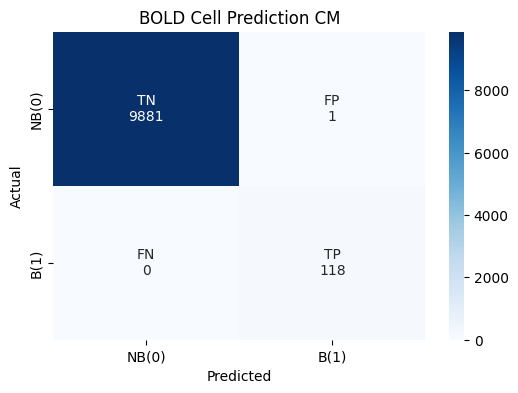


--- Predicted Grid (1 = Bold, 0 = Not Bold) ---


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,1,1,1,1,1,1,1,1,1,1,1,1,1,1
4,0,0,1,1,1,1,1,1,1,1,1,1,1,1
5,1,1,1,1,1,1,1,1,1,1,1,1,1,1
6,1,1,0,0,0,0,0,0,0,0,0,0,0,0
7,1,1,0,0,0,0,0,0,0,0,0,0,0,0
8,1,1,0,0,0,0,0,0,0,0,0,0,0,0
9,1,1,0,0,0,0,0,0,0,0,0,0,0,0
10,1,1,0,0,0,0,0,0,0,0,0,0,0,0
11,1,1,0,0,0,0,0,0,0,0,0,0,0,0
12,1,1,0,0,0,0,0,0,0,0,0,0,0,0



--- Actual Grid (1 = Bold, 0 = Not Bold) ---


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,1,1,1,1,1,1,1,1,1,1,1,1,1,1
4,0,0,1,1,1,1,1,1,1,1,1,1,1,1
5,1,1,1,1,1,1,1,1,1,1,1,1,1,1
6,1,1,0,0,0,0,0,0,0,0,0,0,0,0
7,1,1,0,0,0,0,0,0,0,0,0,0,0,0
8,1,1,0,0,0,0,0,0,0,0,0,0,0,0
9,1,1,0,0,0,0,0,0,0,0,0,0,0,0
10,1,1,0,0,0,0,0,0,0,0,0,0,0,0
11,1,1,0,0,0,0,0,0,0,0,0,0,0,0
12,1,1,0,0,0,0,0,0,0,0,0,0,0,0



Filename: ../data/manual_val/ffelbydefermenttype.xls

--- Unique Sigmoid Probabilities for Bold Cells ---
(5,11): 0.998621 | (5,10): 0.998672 | (29,0): 0.998729 | (27,0): 0.998741 | (0,15): 0.998754 | (25,0): 0.998756 | (31,0): 0.998760 | (0,17): 0.998766 | (0,13): 0.998769 | (23,0): 0.998774 | (21,0): 0.998780 | (29,1): 0.998788 | (27,1): 0.998794 | (31,1): 0.998801 | (25,1): 0.998809 | (19,0): 0.998815 | (23,1): 0.998816 | (32,0): 0.998818 | (0,11): 0.998819 | (30,0): 0.998828 | (17,0): 0.998831 | (0,9): 0.998832 | (21,1): 0.998833 | (15,0): 0.998834 | (28,0): 0.998836 | (0,2): 0.998844 | (13,0): 0.998845 | (26,0): 0.998847 | (24,0): 0.998849 | (6,8): 0.998851 | (30,1): 0.998851 | (32,1): 0.998852 | (6,6): 0.998854 | (5,5): 0.998854 | (22,0): 0.998855 | (19,1): 0.998857 | (28,1): 0.998859 | (0,16): 0.998860 | (5,7): 0.998864 | (20,0): 0.998864 | (11,0): 0.998867 | (9,0): 0.998868 | (24,1): 0.998869 | (26,1): 0.998869 | (0,10): 0.998870 | (15,1): 0.998871 | (0,7): 0.998873 | (17,1): 

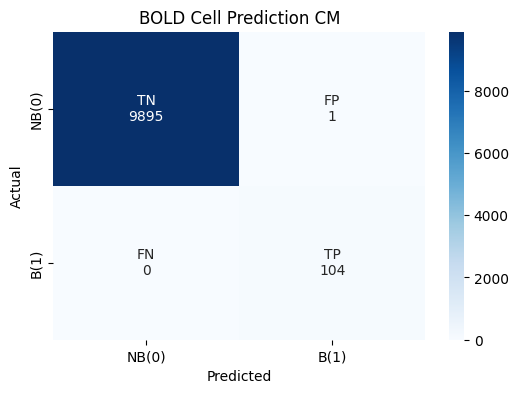


--- Predicted Grid (1 = Bold, 0 = Not Bold) ---


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
5,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
6,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
7,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
8,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
9,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
10,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
11,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
12,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
13,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0



--- Actual Grid (1 = Bold, 0 = Not Bold) ---


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
5,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
6,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
7,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
8,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
9,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
10,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
11,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
12,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
13,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0



Filename: ../data/manual_test/dlportfoliobyrepaymentplan.xls

--- Unique Sigmoid Probabilities for Bold Cells ---
(5,17): 0.012436 | (5,16): 0.031573 | (5,9): 0.968256 | (5,8): 0.990137 | (5,7): 0.992208 | (5,15): 0.995806 | (5,6): 0.997563 | (5,14): 0.998041 | (5,5): 0.998530 | (5,19): 0.998553 | (37,0): 0.998556 | (27,0): 0.998656 | (35,0): 0.998657 | (0,21): 0.998661 | (29,0): 0.998672 | (25,0): 0.998693 | (5,18): 0.998697 | (31,0): 0.998704 | (37,1): 0.998705 | (33,0): 0.998710 | (23,0): 0.998718 | (0,19): 0.998721 | (21,0): 0.998752 | (5,3): 0.998753 | (0,15): 0.998755 | (19,0): 0.998759 | (0,17): 0.998767 | (0,13): 0.998770 | (35,1): 0.998771 | (5,4): 0.998773 | (27,1): 0.998774 | (29,1): 0.998784 | (31,1): 0.998788 | (17,0): 0.998799 | (33,1): 0.998801 | (30,0): 0.998802 | (23,1): 0.998804 | (25,1): 0.998804 | (28,0): 0.998810 | (7,0): 0.998812 | (15,0): 0.998817 | (34,0): 0.998817 | (36,0): 0.998818 | (0,11): 0.998820 | (5,2): 0.998822 | (13,0): 0.998829 | (21,1): 0.998829 | (

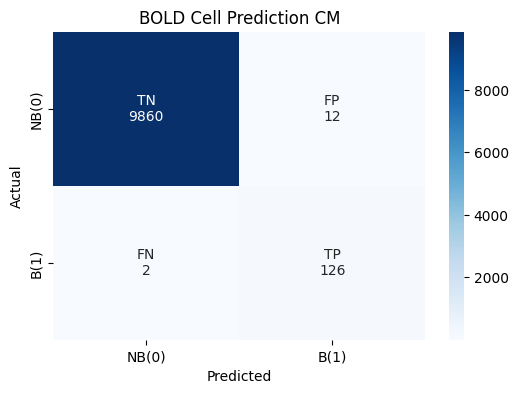


--- Predicted Grid (1 = Bold, 0 = Not Bold) ---


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21
0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
5,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1
6,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
7,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
8,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0
9,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
10,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0
11,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
12,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0
13,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0



--- Actual Grid (1 = Bold, 0 = Not Bold) ---


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21
0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
5,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
6,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
7,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
8,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
9,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
10,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
11,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
12,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
13,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [11]:
# Import
from utils import inferutil

importlib.reload(inferutil)
from utils.inferutil import infer_full, infer_one

test_config['save_dir'] = "../models/"
test_config['save_name'] = "test_model"


# Params
loc = 0
thresh = 0.9

# Inference on single position of train_loader
infer_one(
    trained_model=trained_model,
    infer_loader=train_ds,
    loc=loc,
    threshold=thresh,
    device=test_config["DEVICE"],
    config=test_config,
    disp_sig=True,
)
# Inference on single position of val_loader
infer_one(
    trained_model=trained_model,
    infer_loader=val_ds,
    loc=loc,
    threshold=thresh,
    device=test_config["DEVICE"],
    config=test_config,
    disp_sig=True,
)
# Inference on single position of test_loader
infer_one(
    trained_model=trained_model,
    infer_loader=test_ds,
    loc=loc,
    threshold=thresh,
    device=test_config["DEVICE"],
    config=test_config,
    disp_sig=True,
)

Batch Inference: 100%|██████████| 20/20 [00:02<00:00,  8.54it/s]



--- Aggregated Metrics Across All Batches ---

NB to B ratio: Predicted = 396695:3305 | Actual = 396714:3286
Accuracy: 100.00% | Precision: 99.48% | Recall: 100.00% | F1-Score: 1.00



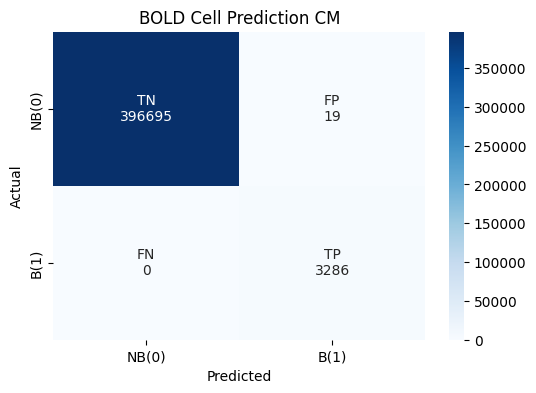

Batch Inference: 100%|██████████| 3/3 [00:00<00:00, 10.18it/s]



--- Aggregated Metrics Across All Batches ---

NB to B ratio: Predicted = 49600:400 | Actual = 49602:398
Accuracy: 100.00% | Precision: 99.59% | Recall: 100.00% | F1-Score: 1.00



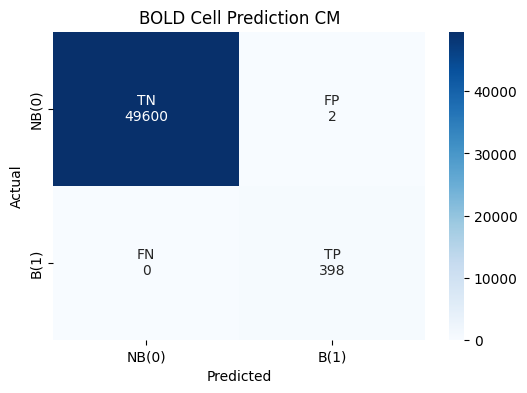

Batch Inference: 100%|██████████| 3/3 [00:00<00:00, 10.18it/s]



--- Aggregated Metrics Across All Batches ---

NB to B ratio: Predicted = 49595:405 | Actual = 49606:394
Accuracy: 99.98% | Precision: 97.87% | Recall: 99.65% | F1-Score: 0.99



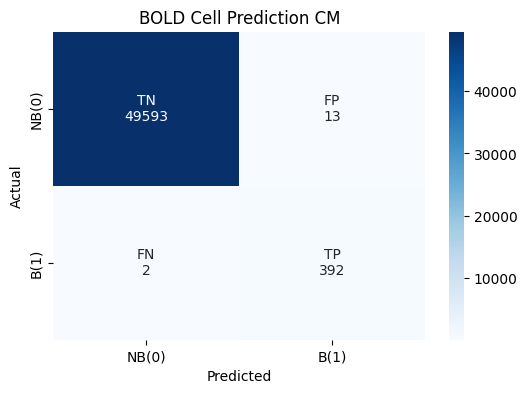

In [12]:
DEVICE = test_config["DEVICE"]
batch_size = test_config["batch_size"]

# Infer across all examples of train_loader
infer_full(
    trained_model=trained_model,
    infer_loader=train_ds,
    batch_size=batch_size,
    threshold=thresh,
    device=DEVICE,
    config=test_config,
)

# Infer across all examples of val_loader
infer_full(
    trained_model=trained_model,
    infer_loader=val_ds,
    batch_size=batch_size,
    threshold=thresh,
    device=DEVICE,
    config=test_config,
)

# Infer across all examples of test_loader
infer_full(
    trained_model=trained_model,
    infer_loader=test_ds,
    batch_size=batch_size,
    threshold=thresh,
    device=DEVICE,
    config=test_config,
)